# RotaSeca — Previsão de alagamentos com regressão linear e logística

**Global Solution 2026.2 · FIAP · Data Science & Statistical Computing · Engenharia de Software (2º ano, Fev)**

**CitizenTech:** RotaSeca, que manda alertas de alagamento e indica rotas seguras para quem mora no Parque Novo Mundo (Zona Norte de São Paulo).

| Integrante | RM |
|---|---|
| Christian Schunck de Almeida | RM563850 |
| Guilherme Vilela Perez | RM564422 |
| Gustavo Panham Dourado | RM563904 |
| Paulo Cesar de Govea Junior | RM566034 |
| Thomas Jeferson Santana Wang | RM565104 |

**Base:** `rotaseca_chuvas_alagamentos.csv`, gerada por `gerar_dados.py` (semente fixa 2026). É uma base **sintética**: os combinados da GS não permitem dados pessoais reais, e os dados públicos de alagamento de São Paulo (CGE/CET) não trazem, por ponto e por hora, a altura da lâmina d'água junto com a chuva e os bueiros obstruídos. A geração segue regras físicas simples, com faixas de chuva usuais em boletins meteorológicos (fraca < 5 mm/h, moderada 5–25, forte 25–50, muito forte > 50) e as cotas críticas dos 6 pontos de risco cadastrados no banco Oracle da solução.

## 1. Contexto, perguntas e variáveis-alvo

Em dias de chuva forte, os moradores do Parque Novo Mundo só descobrem que uma rua alagou quando já estão nela. A RotaSeca recebe medições de sensores e relatos dos moradores. Para **avisar antes**, precisamos estimar a situação de cada ponto a partir da chuva que está caindo.

**Perguntas:**

1. **Quanto de água vai acumular** no ponto nesta hora? → *regressão linear*, alvo numérico **`lamina_agua_cm`** (altura da lâmina d'água, em cm).
2. **Qual a probabilidade de a rua ficar intransitável** (água acima da cota crítica do ponto, com a via interditada por um agente)? → *regressão logística*, alvo binário **`intransitavel`** (1 = intransitável, 0 = transitável).
3. **Quais ações** (alertas, limpeza de bueiros, prioridade de pontos) reduzem o risco para quem anda a pé, idosos e pessoas com deficiência?

**Variáveis explicativas** (todas conhecidas **no momento da previsão**):

| Variável | Significado |
|---|---|
| `chuva_1h_mm` | chuva na última hora (pluviômetro) |
| `chuva_3h_mm` | chuva acumulada nas últimas 3 horas |
| `chuva_24h_mm` | chuva acumulada nas últimas 24 horas (solo encharcado) |
| `bueiros_obstruidos` | relatos de bueiros entupidos perto do ponto (zeladoria) |
| `area_impermeavel_pct` | percentual de área asfaltada/concretada no entorno |
| `distancia_corrego_m` | distância até o córrego |
| `altitude_relativa_m` | altura do ponto em relação à baixada do bairro |
| `cota_critica_cm` | altura de água a partir da qual o ponto vira intransitável |
| `estacao_chuvosa` | 1 de outubro a março |

> **Atenção ao vazamento de dados:** `lamina_agua_cm` **não** entra como variável explicativa da regressão logística. Ela é medida no mesmo instante do evento e praticamente define `intransitavel`. Usá-la seria "olhar a resposta".

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, r2_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, mean_squared_error, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
AZUL, LARANJA, VERMELHO, CINZA = "#0b3c5d", "#d97706", "#b3261e", "#6b7280"
SEMENTE = 2026

## 2. Carregamento e exploração dos dados

In [2]:
df = pd.read_csv("rotaseca_chuvas_alagamentos.csv", parse_dates=["data_hora"])
print(f"{df.shape[0]} linhas x {df.shape[1]} colunas | período: {df.data_hora.min():%d/%m/%Y} a {df.data_hora.max():%d/%m/%Y}")
df.head()

19200 linhas x 15 colunas | período: 01/01/2024 a 31/12/2025


,data_hora,id_ponto,nome_ponto,cota_critica_cm,area_impermeavel_pct,distancia_corrego_m,altitude_relativa_m,estacao_chuvosa,hora,chuva_1h_mm,chuva_3h_mm,chuva_24h_mm,bueiros_obstruidos,lamina_agua_cm,intransitavel
0,2024-01-01 08:00:00,1,Baixada do corrego,30,88,15,0.500,1,8,2.600,7.600,36.300,1.000,6.200,0
1,2024-01-01 08:00:00,2,Passagem sob a rodovia,40,95,120,-1.500,1,8,2.600,7.600,36.300,3.000,15.300,0
2,2024-01-01 08:00:00,3,Rua do mercado,25,82,160,1.000,1,8,2.600,7.600,36.300,1.000,0.000,0
3,2024-01-01 08:00:00,4,Acesso a escola,25,70,240,2.000,1,8,2.600,7.600,36.300,2.000,0.000,0
4,2024-01-01 08:00:00,5,Ponto de onibus da avenida,30,90,300,1.500,1,8,2.600,7.600,36.300,1.000,6.900,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19200 entries, 0 to 19199
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   data_hora             19200 non-null  datetime64[us]
 1   id_ponto              19200 non-null  int64         
 2   nome_ponto            19200 non-null  str           
 3   cota_critica_cm       19200 non-null  int64         
 4   area_impermeavel_pct  19200 non-null  int64         
 5   distancia_corrego_m   19200 non-null  int64         
 6   altitude_relativa_m   19200 non-null  float64       
 7   estacao_chuvosa       19200 non-null  int64         
 8   hora                  19200 non-null  int64         
 9   chuva_1h_mm           19200 non-null  float64       
 10  chuva_3h_mm           19200 non-null  float64       
 11  chuva_24h_mm          19170 non-null  float64       
 12  bueiros_obstruidos    19170 non-null  float64       
 13  lamina_agua_cm        19200

In [4]:
print("Valores ausentes por coluna:")
print(df.isna().sum()[lambda s: s > 0])
print("\nLinhas duplicadas:", df.duplicated().sum())
df.describe().T

Valores ausentes por coluna:
chuva_24h_mm          30
bueiros_obstruidos    30
dtype: int64

Linhas duplicadas: 0


,count,mean,min,25%,50%,75%,max,std
data_hora,19200,2025-01-01 22:34:00.750000,2024-01-01 08:00:00,2024-07-14 11:45:00,2024-12-30 09:30:00,2025-06-27 19:15:00,2025-12-31 22:00:00,NaN
id_ponto,"19,200.000",3.500,1.000,2.000,3.500,5.000,6.000,1.708
cota_critica_cm,"19,200.000",28.333,20.000,25.000,27.500,30.000,40.000,6.236
area_impermeavel_pct,"19,200.000",83.333,70.000,75.000,85.000,90.000,95.000,8.673
distancia_corrego_m,"19,200.000",172.500,15.000,120.000,180.000,240.000,300.000,90.637
altitude_relativa_m,"19,200.000",1.000,-1.500,0.500,1.250,2.000,2.500,1.291
estacao_chuvosa,"19,200.000",0.723,0.000,0.000,1.000,1.000,1.000,0.448
hora,"19,200.000",12.584,0.000,7.000,14.000,18.000,23.000,6.722
chuva_1h_mm,"19,200.000",10.497,0.200,1.400,3.300,11.200,118.600,16.036
chuva_3h_mm,"19,200.000",17.385,0.300,4.900,8.700,20.525,153.600,20.400


In [5]:
resumo = (df.groupby(["id_ponto", "nome_ponto"])
            .agg(registros=("intransitavel", "size"), lamina_media_cm=("lamina_agua_cm", "mean"),
                 lamina_max_cm=("lamina_agua_cm", "max"), cota_critica_cm=("cota_critica_cm", "first"),
                 taxa_intransitavel=("intransitavel", "mean"))
            .reset_index())
resumo

,id_ponto,nome_ponto,registros,lamina_media_cm,lamina_max_cm,cota_critica_cm,taxa_intransitavel
0,1,Baixada do corrego,3200,16.958,95.900,30,0.147
1,2,Passagem sob a rodovia,3200,21.153,95.200,40,0.103
2,3,Rua do mercado,3200,9.995,90.500,25,0.126
3,4,Acesso a escola,3200,4.979,71.000,25,0.074
4,5,Ponto de onibus da avenida,3200,6.511,74.100,30,0.068
5,6,Entorno da UBS,3200,5.274,77.200,20,0.107


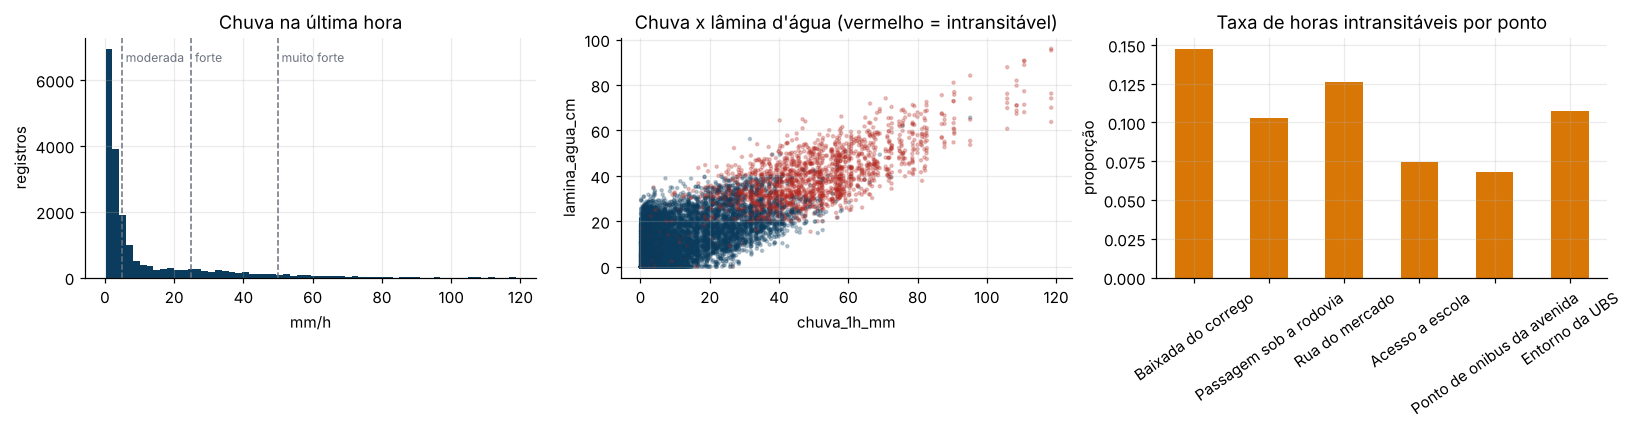

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df.chuva_1h_mm, bins=60, color=AZUL)
ax[0].set(title="Chuva na última hora", xlabel="mm/h", ylabel="registros")
for limite, rotulo in [(5, "moderada"), (25, "forte"), (50, "muito forte")]:
    ax[0].axvline(limite, color=CINZA, ls="--", lw=1)
    ax[0].text(limite + 1, ax[0].get_ylim()[1] * 0.9, rotulo, fontsize=8, color=CINZA)
ax[1].scatter(df.chuva_1h_mm, df.lamina_agua_cm, s=4, alpha=0.25,
              c=np.where(df.intransitavel == 1, VERMELHO, AZUL))
ax[1].set(title="Chuva x lâmina d'água (vermelho = intransitável)", xlabel="chuva_1h_mm", ylabel="lamina_agua_cm")
resumo.plot.bar(x="nome_ponto", y="taxa_intransitavel", ax=ax[2], color=LARANJA, legend=False)
ax[2].set(title="Taxa de horas intransitáveis por ponto", xlabel="", ylabel="proporção")
ax[2].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

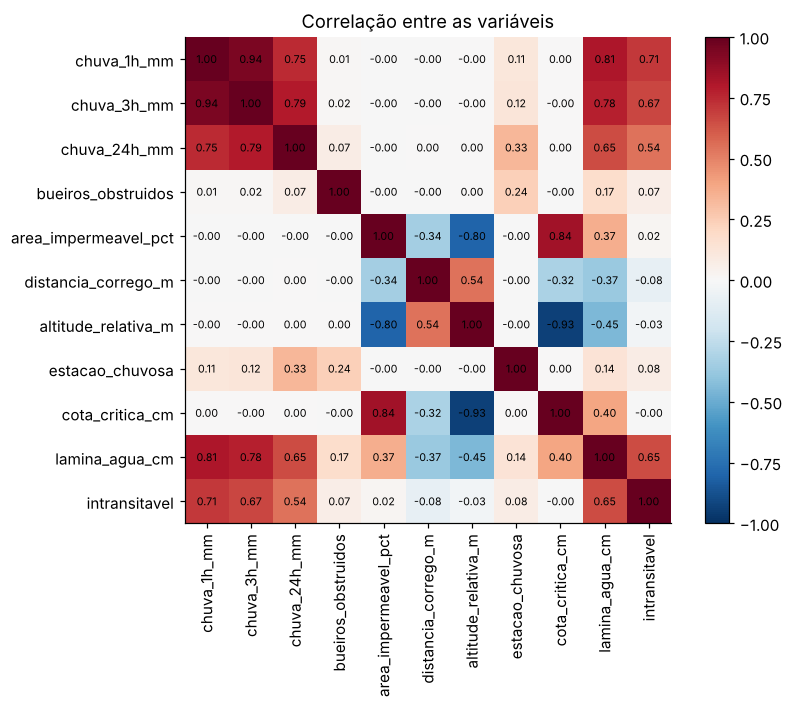

In [7]:
numericas = ["chuva_1h_mm", "chuva_3h_mm", "chuva_24h_mm", "bueiros_obstruidos", "area_impermeavel_pct",
             "distancia_corrego_m", "altitude_relativa_m", "estacao_chuvosa", "cota_critica_cm",
             "lamina_agua_cm", "intransitavel"]
corr = df[numericas].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=90); ax.set_yticks(range(len(numericas)), numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Correlação entre as variáveis"); ax.grid(False)
plt.tight_layout(); plt.show()

**O que a exploração mostra:**

- A maior parte das horas de chuva é fraca. Os poucos temporais concentram os alagamentos (cauda longa à direita).
- A lâmina d'água cresce com a chuva da última hora (correlação forte), e o acumulado de 3 e 24 horas e os bueiros obstruídos também contribuem.
- A *Passagem sob a rodovia* e a *Baixada do córrego* têm as maiores lâminas. O *Entorno da UBS* tem a cota crítica mais baixa (20 cm), então fica intransitável com menos água. Isso é importante para quem usa cadeira de rodas.
- `chuva_1h`, `chuva_3h` e `chuva_24h` são correlacionadas entre si. As características fixas dos pontos (altitude, impermeabilização e cota crítica) também são, porque só existem 6 pontos. Essa multicolinearidade não atrapalha a previsão, mas pede cuidado ao interpretar cada coeficiente isoladamente.
- Há 60 valores ausentes (falhas de sensor) em `chuva_24h_mm` e `bueiros_obstruidos`. Eles serão imputados **dentro do pipeline**, usando só o treino.

## 3. Preparação dos dados e separação treino/teste (sem vazamento)

Decisões para **evitar vazamento de dados**:

1. **Divisão temporal, não aleatória.** Os registros são horas consecutivas e chuvas de horas vizinhas se parecem. Com um sorteio aleatório, o modelo "veria o futuro" de um mesmo temporal. Treinamos com os primeiros 80% do período e testamos nos últimos 20%, como aconteceria em produção. Todos os pontos da mesma hora ficam do mesmo lado do corte.
2. **Imputação e padronização dentro de um `Pipeline`.** A mediana usada para preencher ausentes e a média/desvio da padronização são calculadas **só com o treino** e depois aplicadas ao teste.
3. **Sem variáveis do próprio desfecho.** `lamina_agua_cm` não entra na logística, e `intransitavel` não entra na linear.
4. **Escolha do limiar de alerta só com dados de treino**, usando validação cruzada temporal (`TimeSeriesSplit`): cada fatia é prevista por um modelo treinado só com o passado dela. O conjunto de teste só é usado uma vez, no fim.
5. **`cota_critica_cm` só na logística.** A cota não muda a quantidade de água que chega ao ponto (por isso fica fora da linear), mas define a partir de quando a rua fecha (por isso entra na logística). É uma característica fixa do ponto, conhecida antes do evento.

In [8]:
FEATURES_REG = ["chuva_1h_mm", "chuva_3h_mm", "chuva_24h_mm", "bueiros_obstruidos", "area_impermeavel_pct",
                "distancia_corrego_m", "altitude_relativa_m", "estacao_chuvosa"]
FEATURES = FEATURES_REG + ["cota_critica_cm"]   # logística
ALVO_REG, ALVO_CLF = "lamina_agua_cm", "intransitavel"

df = df.sort_values(["data_hora", "id_ponto"]).reset_index(drop=True)
corte = df.data_hora.quantile(0.80)
treino = df[df.data_hora <= corte].copy()
teste = df[df.data_hora > corte].copy()

assert treino.data_hora.max() < teste.data_hora.min(), "treino e teste se sobrepõem no tempo"

tabela = pd.DataFrame({
    "conjunto": ["treino", "teste"],
    "linhas": [len(treino), len(teste)],
    "início": [d.data_hora.min().strftime("%d/%m/%Y") for d in (treino, teste)],
    "fim": [d.data_hora.max().strftime("%d/%m/%Y") for d in (treino, teste)],
    "% intransitável": [d[ALVO_CLF].mean() * 100 for d in (treino, teste)],
})
tabela

,conjunto,linhas,início,fim,% intransitável
0,treino,15360,01/01/2024,01/09/2025,9.987
1,teste,3840,01/09/2025,31/12/2025,12.214


In [9]:
def preprocessamento():
    """Etapas ajustadas apenas com os dados passados no .fit() (o treino)."""
    return [("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler())]

X_treino_reg, X_teste_reg = treino[FEATURES_REG], teste[FEATURES_REG]
X_treino, X_teste = treino[FEATURES], teste[FEATURES]
y_treino_reg, y_teste_reg = treino[ALVO_REG], teste[ALVO_REG]
y_treino_clf, y_teste_clf = treino[ALVO_CLF], teste[ALVO_CLF]
print("Ausentes no treino antes do pipeline:", int(X_treino.isna().sum().sum()),
      "| no teste:", int(X_teste.isna().sum().sum()))

Ausentes no treino antes do pipeline: 46 | no teste: 14


## 4. Regressão linear — quanto de água vai acumular

In [10]:
modelo_linear = Pipeline(preprocessamento() + [("modelo", LinearRegression())])
modelo_linear.fit(X_treino_reg, y_treino_reg)
prev_reg = modelo_linear.predict(X_teste_reg)

baseline_reg = DummyRegressor(strategy="mean").fit(X_treino_reg, y_treino_reg)
prev_base = baseline_reg.predict(X_teste_reg)

def metricas_reg(y, p):
    return {"MAE (cm)": mean_absolute_error(y, p), "RMSE (cm)": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}

met_reg = pd.DataFrame({"Regressão linear": metricas_reg(y_teste_reg, prev_reg),
                        "Baseline (média do treino)": metricas_reg(y_teste_reg, prev_base)}).T
met_treino = metricas_reg(y_treino_reg, modelo_linear.predict(X_treino_reg))
print(f"No treino: MAE {met_treino['MAE (cm)']:.2f} cm | RMSE {met_treino['RMSE (cm)']:.2f} cm | R² {met_treino['R²']:.3f}")
met_reg

No treino: MAE 3.04 cm | RMSE 3.91 cm | R² 0.907


,MAE (cm),RMSE (cm),R²
Regressão linear,3.052,3.932,0.911
Baseline (média do treino),10.215,13.248,-0.010


In [11]:
# coeficientes na escala original (cm de lâmina por unidade de cada variável)
escala = modelo_linear.named_steps["padronizar"].scale_
coef_pad = modelo_linear.named_steps["modelo"].coef_
coeficientes = pd.DataFrame({"variável": FEATURES_REG, "coef. padronizado": coef_pad,
                             "efeito em cm por unidade": coef_pad / escala}).sort_values(
    "coef. padronizado", key=abs, ascending=False)
coeficientes

,variável,coef. padronizado,efeito em cm por unidade
0,chuva_1h_mm,8.052,0.503
6,altitude_relativa_m,-3.905,-3.025
5,distancia_corrego_m,-2.366,-0.026
3,bueiros_obstruidos,1.998,1.785
1,chuva_3h_mm,1.736,0.086
2,chuva_24h_mm,0.801,0.030
4,area_impermeavel_pct,0.736,0.085
7,estacao_chuvosa,-0.094,-0.201


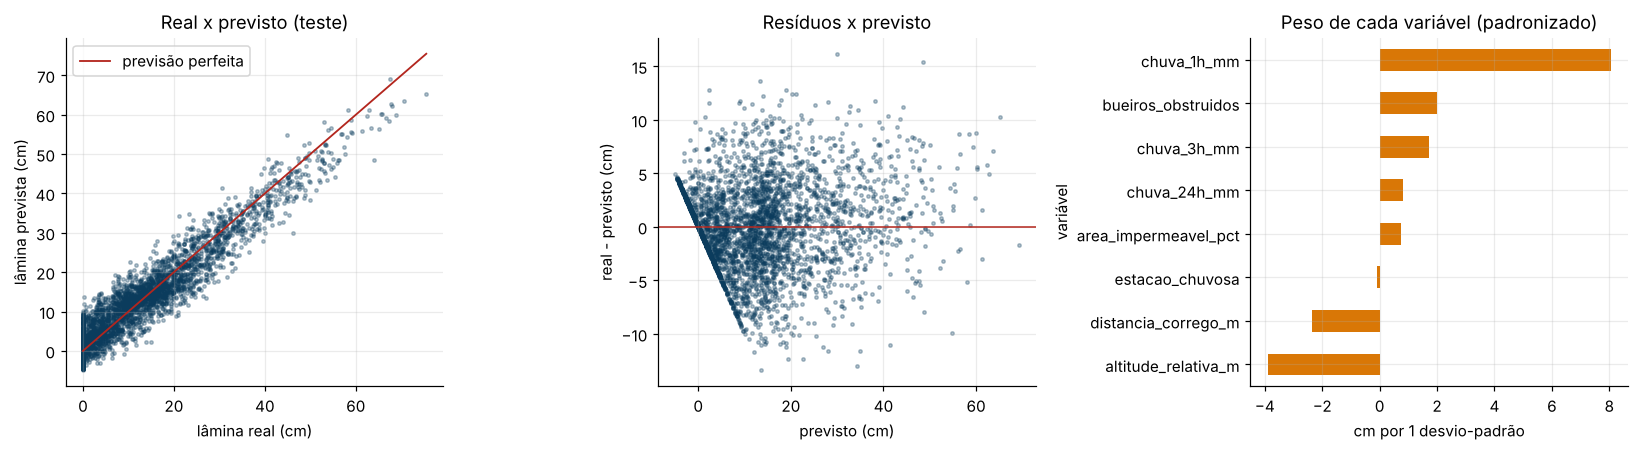

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(y_teste_reg, prev_reg, s=5, alpha=0.3, color=AZUL)
lim = [0, max(y_teste_reg.max(), prev_reg.max())]
ax[0].plot(lim, lim, color=VERMELHO, lw=1.2, label="previsão perfeita")
ax[0].set(title="Real x previsto (teste)", xlabel="lâmina real (cm)", ylabel="lâmina prevista (cm)"); ax[0].legend()
residuos = y_teste_reg - prev_reg
ax[1].scatter(prev_reg, residuos, s=5, alpha=0.3, color=AZUL); ax[1].axhline(0, color=VERMELHO, lw=1)
ax[1].set(title="Resíduos x previsto", xlabel="previsto (cm)", ylabel="real - previsto (cm)")
coeficientes.set_index("variável")["coef. padronizado"].sort_values().plot.barh(ax=ax[2], color=LARANJA)
ax[2].set(title="Peso de cada variável (padronizado)", xlabel="cm por 1 desvio-padrão")
plt.tight_layout(); plt.show()

In [13]:
erro_por_ponto = (teste.assign(previsto=prev_reg, erro_abs=np.abs(residuos))
                  .groupby("nome_ponto")[["lamina_agua_cm", "previsto", "erro_abs"]].mean()
                  .rename(columns={"lamina_agua_cm": "real médio", "previsto": "previsto médio", "erro_abs": "MAE"}))
erro_por_ponto

,real médio,previsto médio,MAE
nome_ponto,,,
Acesso a escola,5.890,5.960,2.638
Baixada do corrego,18.140,17.915,3.537
Entorno da UBS,5.928,5.883,2.593
Passagem sob a rodovia,22.517,21.738,3.620
Ponto de onibus da avenida,7.682,7.695,2.537
Rua do mercado,11.092,12.087,3.385


**Interpretação da regressão linear:**

- O modelo explica cerca de 91% da variação da lâmina d'água no período de teste (R² ≈ 0,91). O erro médio absoluto é de cerca de 3 cm (RMSE ≈ 3,9 cm), contra mais de 10 cm do baseline que sempre prevê a média. Treino e teste têm métricas praticamente iguais, então **não há sinal de sobreajuste**.
- A **chuva da última hora** é o fator mais forte: cada 1 mm/h a mais soma cerca de 0,5 cm de água no ponto. Um temporal de 40 mm/h acrescenta uns 20 cm só por esse fator.
- Os **bueiros obstruídos** somam cerca de 1,8 cm cada. É o único fator que a zeladoria consegue mudar antes da chuva.
- Pontos mais altos acumulam menos água (cerca de 3 cm a menos por metro de altitude), assim como os mais distantes do córrego. Áreas mais impermeabilizadas acumulam mais.
- **Limitação visível no gráfico de resíduos:** a lâmina nunca é negativa, mas a reta pode prever valores abaixo de zero em chuvas fracas. Perto de 0 cm os resíduos formam um "piso". Para o uso da RotaSeca isso pesa pouco, porque o que importa são as chuvas fortes, onde o modelo é mais preciso. Mesmo assim, as previsões devem ser cortadas em 0 na API.

## 5. Regressão logística — probabilidade de a rua ficar intransitável

In [14]:
modelo_logistico = Pipeline(preprocessamento() + [("modelo", LogisticRegression(max_iter=2000, random_state=SEMENTE))])
modelo_logistico.fit(X_treino, y_treino_clf)
prob_teste = modelo_logistico.predict_proba(X_teste)[:, 1]
prev_05 = (prob_teste >= 0.5).astype(int)

baseline_clf = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino_clf)
print("Baseline (sempre 'transitável'): acurácia",
      f"{(baseline_clf.predict(X_teste) == y_teste_clf).mean():.3f}, mas recall = 0: nunca avisa ninguém.\n")
print("Limiar padrão 0,5 — conjunto de teste")
print(classification_report(y_teste_clf, prev_05, target_names=["transitável", "intransitável"], digits=3))
print(f"ROC AUC: {roc_auc_score(y_teste_clf, prob_teste):.3f}")

Baseline (sempre 'transitável'): acurácia 0.878, mas recall = 0: nunca avisa ninguém.

Limiar padrão 0,5 — conjunto de teste
               precision    recall  f1-score   support

  transitável      0.963     0.986     0.975      3371
intransitável      0.881     0.727     0.797       469

     accuracy                          0.955      3840
    macro avg      0.922     0.857     0.886      3840
 weighted avg      0.953     0.955     0.953      3840

ROC AUC: 0.940


### Escolha do limiar de alerta

Para a RotaSeca, **deixar de avisar** uma rua intransitável (falso negativo) é muito pior que um alarme a mais (falso positivo): um idoso ou um cadeirante pode ficar preso na água. Por isso escolhemos o limiar que maximiza o **F2-score**, uma média entre precisão e recall que dá **peso dobrado ao recall**.

O limiar é escolhido com previsões *fora da amostra* do próprio treino. Com `TimeSeriesSplit` (5 dobras), cada bloco de tempo é previsto por um modelo que só viu os blocos anteriores. Assim o teste não participa da escolha, e o limiar é avaliado em várias estações do ano, não só em um período seco.

In [15]:
prob_oof = np.full(len(treino), np.nan)
for idx_passado, idx_futuro in TimeSeriesSplit(n_splits=5).split(X_treino):
    m = Pipeline(preprocessamento() + [("modelo", LogisticRegression(max_iter=2000, random_state=SEMENTE))])
    m.fit(X_treino.iloc[idx_passado], y_treino_clf.iloc[idx_passado])
    prob_oof[idx_futuro] = m.predict_proba(X_treino.iloc[idx_futuro])[:, 1]
avaliados = ~np.isnan(prob_oof)   # o primeiro bloco não tem passado para treinar
precisao, revocacao, limiares = precision_recall_curve(y_treino_clf.values[avaliados], prob_oof[avaliados])
f2 = (5 * precisao * revocacao / np.maximum(4 * precisao + revocacao, 1e-12))[:-1]
LIMIAR = float(limiares[np.argmax(f2)])
print(f"Previsões fora da amostra no treino: {avaliados.sum()} | limiar de maior F2: {LIMIAR:.3f} "
      f"(precisão {precisao[np.argmax(f2)]:.3f}, recall {revocacao[np.argmax(f2)]:.3f})")

prev_lim = (prob_teste >= LIMIAR).astype(int)
met_clf = pd.DataFrame({
    "limiar 0,5": [precision_score(y_teste_clf, prev_05), recall_score(y_teste_clf, prev_05), f1_score(y_teste_clf, prev_05)],
    f"limiar {LIMIAR:.2f} (alerta)": [precision_score(y_teste_clf, prev_lim), recall_score(y_teste_clf, prev_lim),
                                       f1_score(y_teste_clf, prev_lim)],
}, index=["Precisão", "Recall", "F1"]).T
met_clf

Previsões fora da amostra no treino: 12800 | limiar de maior F2: 0.253 (precisão 0.701, recall 0.825)


,Precisão,Recall,F1
"limiar 0,5",0.881,0.727,0.797
limiar 0.25 (alerta),0.713,0.857,0.778


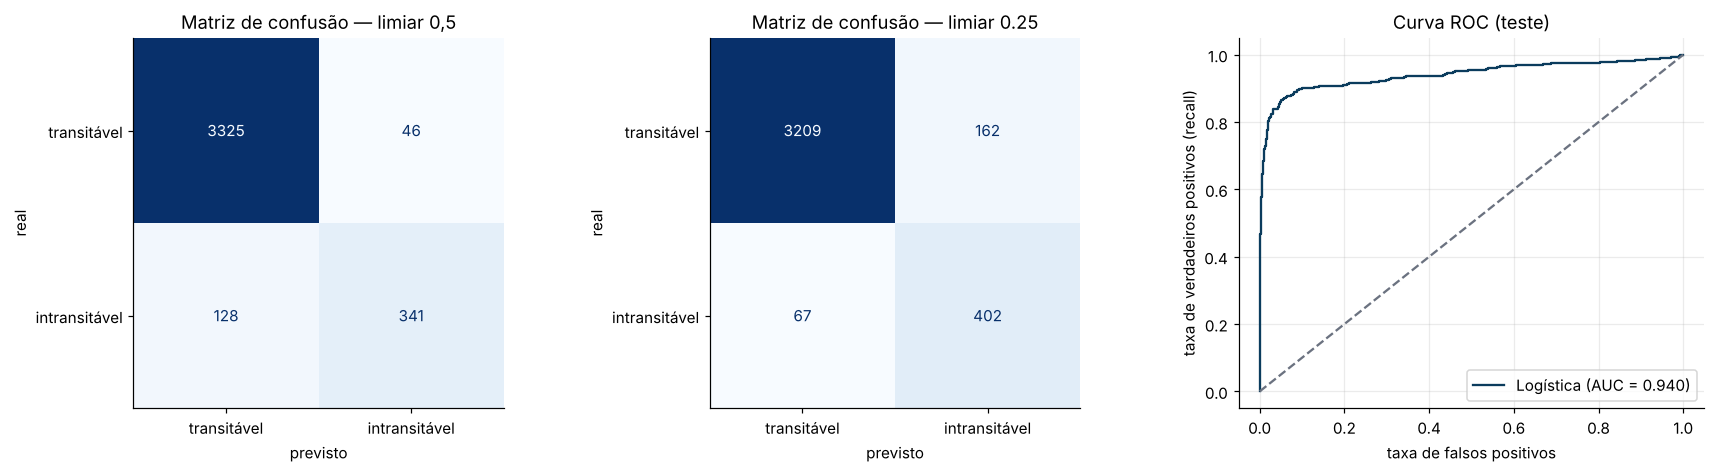

Com o limiar de alerta: 402 horas intransitáveis avisadas, 67 não avisadas, 162 alarmes a mais.


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for eixo, prev, titulo in [(ax[0], prev_05, "Matriz de confusão — limiar 0,5"),
                           (ax[1], prev_lim, f"Matriz de confusão — limiar {LIMIAR:.2f}")]:
    ConfusionMatrixDisplay(confusion_matrix(y_teste_clf, prev), display_labels=["transitável", "intransitável"]).plot(
        ax=eixo, cmap="Blues", colorbar=False, values_format="d")
    eixo.set_title(titulo); eixo.set(xlabel="previsto", ylabel="real"); eixo.grid(False)
fpr, tpr, _ = roc_curve(y_teste_clf, prob_teste)
ax[2].plot(fpr, tpr, color=AZUL, label=f"Logística (AUC = {roc_auc_score(y_teste_clf, prob_teste):.3f})")
ax[2].set(xlabel="taxa de falsos positivos", ylabel="taxa de verdadeiros positivos (recall)"); ax[2].legend(loc="lower right")
ax[2].plot([0, 1], [0, 1], ls="--", color=CINZA); ax[2].set_title("Curva ROC (teste)")
plt.tight_layout(); plt.show()

vn, fp, fn, vp = confusion_matrix(y_teste_clf, prev_lim).ravel()
print(f"Com o limiar de alerta: {vp} horas intransitáveis avisadas, {fn} não avisadas, {fp} alarmes a mais.")

In [17]:
coef_log = modelo_logistico.named_steps["modelo"].coef_[0]
escala_log = modelo_logistico.named_steps["padronizar"].scale_
odds = pd.DataFrame({"variável": FEATURES, "coef. padronizado": coef_log,
                     "razão de chances por unidade": np.exp(coef_log / escala_log)}).sort_values(
    "coef. padronizado", key=abs, ascending=False)
odds

,variável,coef. padronizado,razão de chances por unidade
0,chuva_1h_mm,1.778,1.118
8,cota_critica_cm,-0.880,0.868
6,altitude_relativa_m,-0.525,0.666
5,distancia_corrego_m,-0.519,0.994
3,bueiros_obstruidos,0.416,1.450
4,area_impermeavel_pct,0.265,1.031
2,chuva_24h_mm,0.263,1.010
1,chuva_3h_mm,0.152,1.008
7,estacao_chuvosa,-0.070,0.861


**Interpretação da regressão logística:**

- O modelo separa bem as horas transitáveis das intransitáveis (ROC AUC ≈ 0,94 no teste). A acurácia de 95% sozinha engana: o baseline que nunca avisa já teria 88%. Por isso olhamos precisão, recall e F1 da classe "intransitável".
- Com o limiar padrão de 0,5 o modelo é **conservador**: quando avisa, acerta 88% das vezes (precisão), mas só avisa 73% das ruas que fecharam (recall). Com o **limiar de alerta ≈ 0,25**, escolhido sem olhar o teste, o recall sobe para cerca de 86% e a precisão cai para cerca de 71%. No teste, isso significa avisar 402 horas perigosas em vez de 341 (61 a mais), em troca de 116 alarmes falsos a mais. Para um serviço de proteção, essa troca vale a pena.
- **Razões de chance:** cada 1 mm/h de chuva aumenta a chance em ~12%. Cada bueiro obstruído aumenta a chance em ~45% (razão ≈ 1,45). Cada centímetro a mais de cota crítica reduz a chance em ~13%, o que é coerente: pontos que aguentam mais água fecham menos.

## 6. Recomendações baseadas nas previsões

In [18]:
# Cenário típico de temporal: chuva de 3h e 24h na proporção mediana observada nas horas de chuva forte do TREINO
forte = treino[treino.chuva_1h_mm >= 25]
r3, r24 = (forte.chuva_3h_mm / forte.chuva_1h_mm).median(), (forte.chuva_24h_mm / forte.chuva_1h_mm).median()
pontos = df.drop_duplicates("id_ponto").set_index("id_ponto")
chuvas = np.arange(0, 120.5, 0.5)

def cenario(id_ponto, bueiros):
    p = pontos.loc[id_ponto]
    return pd.DataFrame({"chuva_1h_mm": chuvas, "chuva_3h_mm": chuvas * r3, "chuva_24h_mm": chuvas * r24,
                         "bueiros_obstruidos": bueiros, "area_impermeavel_pct": p.area_impermeavel_pct,
                         "distancia_corrego_m": p.distancia_corrego_m, "altitude_relativa_m": p.altitude_relativa_m,
                         "cota_critica_cm": p.cota_critica_cm, "estacao_chuvosa": 1})[FEATURES]

def chuva_gatilho(id_ponto, bueiros, limiar):
    prob = modelo_logistico.predict_proba(cenario(id_ponto, bueiros))[:, 1]
    acima = np.where(prob >= limiar)[0]
    return float(chuvas[acima[0]]) if len(acima) else np.nan

recomendacao = pd.DataFrame([{
    "ponto": pontos.loc[i].nome_ponto,
    "cota crítica (cm)": int(pontos.loc[i].cota_critica_cm),
    "pré-alerta: chuva (mm/h) — bueiros limpos": chuva_gatilho(i, 0, LIMIAR),
    "pré-alerta: chuva (mm/h) — 3 bueiros obstruídos": chuva_gatilho(i, 3, LIMIAR),
    "chuva p/ 50% de chance — bueiros limpos": chuva_gatilho(i, 0, 0.5),
} for i in pontos.index]).sort_values("pré-alerta: chuva (mm/h) — bueiros limpos")
recomendacao["ganho da limpeza (mm/h a mais de folga)"] = (recomendacao["pré-alerta: chuva (mm/h) — bueiros limpos"]
                                                           - recomendacao["pré-alerta: chuva (mm/h) — 3 bueiros obstruídos"])
print(f"Proporções usadas no cenário: chuva_3h = {r3:.2f} x chuva_1h | chuva_24h = {r24:.2f} x chuva_1h")
recomendacao

Proporções usadas no cenário: chuva_3h = 1.26 x chuva_1h | chuva_24h = 1.62 x chuva_1h


,ponto,cota crítica (cm),pré-alerta: chuva (mm/h) — bueiros limpos,pré-alerta: chuva (mm/h) — 3 bueiros obstruídos,chuva p/ 50% de chance — bueiros limpos,ganho da limpeza (mm/h a mais de folga)
0,Baixada do corrego,30,27.500,19.500,35.500,8.000
2,Rua do mercado,25,31.500,23.500,39.500,8.000
5,Entorno da UBS,20,34.000,26.000,42.000,8.000
1,Passagem sob a rodovia,40,35.000,27.000,43.000,8.000
3,Acesso a escola,25,40.500,32.500,48.500,8.000
4,Ponto de onibus da avenida,30,42.000,34.000,50.000,8.000


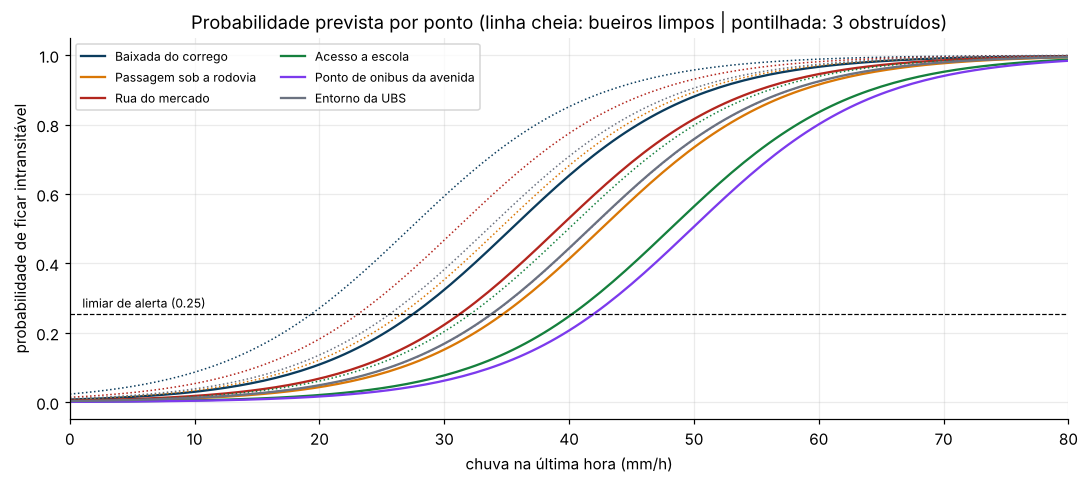

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cores = [AZUL, LARANJA, VERMELHO, "#15803d", "#7c3aed", CINZA]
for cor, i in zip(cores, pontos.index):
    ax.plot(chuvas, modelo_logistico.predict_proba(cenario(i, 0))[:, 1], color=cor, label=pontos.loc[i].nome_ponto)
    ax.plot(chuvas, modelo_logistico.predict_proba(cenario(i, 3))[:, 1], color=cor, ls=":", lw=1)
ax.axhline(LIMIAR, color="black", lw=0.8, ls="--"); ax.text(1, LIMIAR + 0.02, f"limiar de alerta ({LIMIAR:.2f})", fontsize=8)
ax.set(xlim=(0, 80), xlabel="chuva na última hora (mm/h)", ylabel="probabilidade de ficar intransitável",
       title="Probabilidade prevista por ponto (linha cheia: bueiros limpos | pontilhada: 3 obstruídos)")
ax.legend(fontsize=8, ncols=2); plt.tight_layout(); plt.show()

In [20]:
# Efeito previsto de um mutirão de limpeza: quantas horas intransitáveis do TESTE deixariam de ocorrer
# se os bueiros obstruídos fossem zerados (estimativa do modelo, não observação real)
X_limpo = X_teste.copy(); X_limpo["bueiros_obstruidos"] = 0
horas_previstas_hoje = int((modelo_logistico.predict_proba(X_teste)[:, 1] >= 0.5).sum())
horas_previstas_limpo = int((modelo_logistico.predict_proba(X_limpo)[:, 1] >= 0.5).sum())
lamina_hoje = np.clip(modelo_linear.predict(X_teste[FEATURES_REG]), 0, None).mean()
lamina_limpo = np.clip(modelo_linear.predict(X_limpo[FEATURES_REG]), 0, None).mean()
print(f"Horas previstas como intransitáveis no período de teste: {horas_previstas_hoje} -> {horas_previstas_limpo} "
      f"com bueiros limpos ({(1 - horas_previstas_limpo / horas_previstas_hoje) * 100:.0f}% a menos)")
print(f"Lâmina média prevista: {lamina_hoje:.1f} cm -> {lamina_limpo:.1f} cm")

Horas previstas como intransitáveis no período de teste: 387 -> 297 com bueiros limpos (23% a menos)
Lâmina média prevista: 12.1 cm -> 10.1 cm


### Ações recomendadas para a RotaSeca e a subprefeitura

1. **Disparar o pré-alerta pela probabilidade, não só pelo sensor de nível.** Com o pluviômetro, a API pode calcular a probabilidade de cada ponto ficar intransitável e avisar **antes** de a água subir. A tabela acima mostra a chuva (mm/h) que dispara o pré-alerta em cada ponto. A *Baixada do córrego* (≈ 28 mm/h) e a *Rua do mercado* (≈ 32 mm/h) entram em pré-alerta primeiro. O *Entorno da UBS* vem logo depois (≈ 34 mm/h) e tem a menor cota (20 cm), então as mensagens desse ponto devem ir com prioridade para idosos e pessoas com deficiência cadastrados.
2. **Limpar bueiros antes da estação chuvosa, começando pelos pontos de menor folga.** Pelos dois modelos, bueiros obstruídos são o fator de risco **que a cidade consegue controlar**. Três bueiros entupidos antecipam o pré-alerta em cerca de 8 mm/h em qualquer ponto. O valor é igual para todos porque a logística soma os efeitos na escala do *logit*. No período de teste, zerar as obstruções reduziria em cerca de 23% as horas previstas como intransitáveis e baixaria a lâmina média prevista em ~2 cm. Os relatos de zeladoria da RotaSeca (`bueiros_obstruidos`) viram uma lista de prioridade para a subprefeitura.
3. **Usar a previsão de lâmina (regressão linear) para escolher a rota por perfil.** A altura prevista em cm alimenta o módulo de rotas (Dynamic Programming): acima de ~10 cm o trecho é evitado para cadeirantes, e acima da cota crítica é bloqueado para todos.
4. **Medir o impacto:** acompanhar mensalmente o *recall* real dos alertas (ruas que fecharam e tinham sido avisadas) e a antecedência média do aviso em minutos. Esses são os indicadores de impacto da solução.

### Limitações e cuidados

- **Dados sintéticos.** Os coeficientes mostram o método funcionando, não a realidade do bairro. Antes de usar em produção, o modelo precisa ser retreinado com séries reais (pluviômetros do CGE, leituras dos sensores da RotaSeca e interdições registradas pela CET e pelos agentes).
- **Linearidade:** a lâmina real cresce de forma não linear quando a galeria satura, e a reta não respeita o mínimo de 0 cm. Modelos não lineares (árvores, *gradient boosting*) ou uma transformação do alvo podem ajudar.
- **Dependência temporal e espacial:** horas consecutivas e pontos vizinhos não são independentes. As métricas no teste temporal são mais honestas que as de um sorteio aleatório, mas a incerteza real é maior.
- **Erro de registro do alvo:** parte das interdições é anotada com atraso ou não é anotada, o que limita a precisão máxima da logística.
- **Equidade:** o limiar foi escolhido para priorizar o recall, e a decisão de **não deixar ninguém sem aviso** pesa mais que o incômodo de um alarme falso. Ainda assim, excesso de alarmes cansa a população, então o limiar deve ser revisto com o retorno dos moradores.

## 7. Conclusão

- **Regressão linear:** prevê a altura da água em cada ponto com erro médio de ~3 cm em horas que o modelo nunca viu. É útil para decidir **por onde cada perfil de pessoa pode passar**.
- **Regressão logística:** estima a probabilidade de a rua ficar intransitável (ROC AUC ≈ 0,94). Com o limiar de alerta escolhido por validação temporal, avisa cerca de 86% das situações perigosas (mais de 8 em cada 10).
- As previsões levam a **ações concretas**: pré-alerta por chuva, prioridade de limpeza de bueiros e rotas acessíveis. Isso liga a análise de dados ao objetivo da RotaSeca, que é **ninguém ser pego de surpresa pela água no caminho de casa**.